# **TALLER METODO AHP PARA PROBLEMAS MULTIOBJETIVO  DISCRETOS**

#**ELECCION DE CARRO**

Curso: Introducción al Análisis de Decisiones

Universidad Nacional de Colombia, Sede Medellín

Plantilla: Profesora Patricia Jaramillo y estudiante Luis José Mejía (actualización: 13 de julio de 2026)

Desarrollado por: Daniel Fernando Verdecia Goyeneche. Documento: 1006456802

Fecha: 23 de noviembre de 2026

### NOTA, buscar etiqueta: %RELLENAR% para encontrar rapidamente las matrices que debe llenar.



:### Recordatorio teórico

**Problemas multiobjetivo discretos.** El número de alternativas es finito y se listan explícitamente (p. ej. *¿cuál proveedor elegir?*). Se resumen en una **matriz de consecuencias** (criterios en filas, alternativas en columnas), a diferencia de los problemas continuos, que se modelan con ecuaciones.

**Método AHP (Saaty, 1980).** Jerarquiza el problema en niveles (objetivo >> criterios >> subcriterios >> alternativas) para que el decisor estructure y clarifique el problema. Los criterios de un mismo nivel deben ser **independientes**. Sus pasos son:

1. Diseñar el árbol jerárquico de criterios.
2. Definir las alternativas en el último nivel del árbol.
3. Asignar pesos a los vínculos del árbol (pesos locales y globales).
4. Valorar las alternativas respecto a cada criterio.
5. Normalizar la matriz de consecuencias.
6. Valorar las alternativas por una regla de decisión (AHP por defecto es con suma ponderada).
7. Análisis de sensibilidad.
8. Decisión.

**Escala de comparación pareada de Saaty.** Al comparar dos elementos $i$ y $j$ respecto al nivel superior que comparten, se asigna un valor de la siguiente escala (y su recíproco en la celda simétrica):

| Si $i$ es ... que $j$        | Valor |
|------------------------------|:-----:|
| Igualmente importante        | 1 |
| Apenas más importante        | 3 |
| Bastante más importante      | 5 |
| Mucho más importante         | 7 |
| Absolutamente más importante | 9 |

Los números pares (2, 4, 6, 8) representan situaciones intermedias. Si $a_{ij}$ es el juicio de la fila $i$ frente a la columna $j$, entonces $a_{ji} = 1/a_{ij}$ y la diagonal es 1.


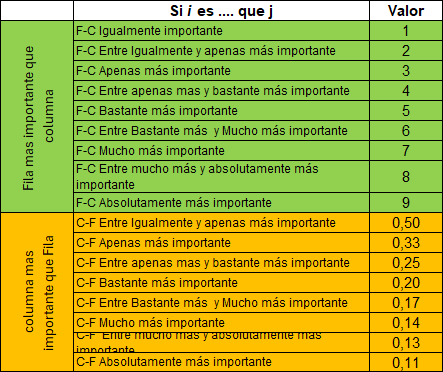

## **Aplicación del Método AHP: Caso de selección de un automóvil**


%RELLENAR%Esta plantilla está muy completa. Usted solo debe:

1.	Construya las matrices de comparación pareada del caso del automóvil (matriz principal Costo/Seguridad/Capacidad, y los macrocriterios Costo y Capacidad) con sus propias preferencias y verifique con analizar_consistencia que cada una cumple CR≤0.10. Si alguna no cumple, ajuste sus juicios y explique qué cambió.

2.	Cambie el modelo y datos de la primera columna de las alternativas: Apóyese en internet. Si no encuentra un dato asúmalo de forma realista

3.	Analice la jerarquía y elija su carro.


4.	Haga análisis de sensibilidad cambiando los pesos ligeramente por encima y por debajo. Sigue ganando la misma alternativa? (Es decir, es robusta al cambio de pesos?)

5.	Haga análisis de sensibilidad, mediante simulación de Montecarlo. ¿Cuál es la alternativa más robusta al cambio de pesos? _________________________ ¿Por qué?

### Datos del caso

Uso los mismos seis carros del taller anterior (programación de compromiso). Son seis Toyota modelo 2026 que mantienen los tipos de vehículo del enunciado: sedán, sedán híbrido, SUV de tres filas, SUV compacta, SUV mediana y minivan.

| Macrocriterio | Sentido | Criterio | Unidad | Corolla | Corolla Híbrido | Grand Highlander | Corolla Cross | 4Runner | Sienna |
|---|---|---|---|:---:|:---:|:---:|:---:|:---:|:---:|
| Costo | min | Precio de compra | USD | 24.320 | 26.170 | 43.355 | 26.485 | 43.365 | 41.915 |
| Costo | min | Combustible | USD en 5 años | 4.365 | 3.126 | 6.550 | 4.864 | 6.945 | 4.306 |
| Costo | min | Mantenimiento | USD en 5 años | 1.780 | 2.294 | 2.219 | 1.831 | 1.723 | 1.645 |
| Seguridad | max | Seguridad | estrellas NHTSA (1 a 5) | 5 | 5 | 5 | 5 | 4 | 5 |
| Capacidad | max | Carga | pies cúbicos | 13,1 | 13,1 | 20,6 | 24,0 | 48,4 | 33,5 |
| Capacidad | max | Pasajeros | cantidad | 5 | 5 | 8 | 5 | 5 | 8 |

**De dónde salen los datos**

* Precio de compra: precio base (MSRP) de la versión de entrada más el cargo de entrega, según las fichas técnicas 2026 de Toyota (`engage.toyota.com`, *Sourcebook* 2026).
* Combustible y mantenimiento: costo estimado a cinco años de Kelley Blue Book (*5-Year Cost to Own*, 2026). El enunciado pone el combustible en "USD / MPG", pero los números de la tabla son millas por galón, y ahí un valor alto es bueno. Como el criterio es un costo, usé el gasto en dólares, igual que en el taller anterior. Para el mantenimiento no encontré el costo de neumáticos cada 60.000 millas por modelo, así que también usé el dato de KBB.
* Seguridad: calificación global de la NHTSA (*5-Star Safety Ratings*), que va de 1 a 5 como en el enunciado.
* Carga: espacio detrás de la última fila de asientos en uso, y pasajeros: número de plazas. Ambos de las fichas técnicas de Toyota 2026.
* Los datos se consultaron el 13 de noviembre de 2026 para el taller anterior. Las calificaciones de la NHTSA las volví a revisar el 23 de noviembre de 2026 y siguen iguales.
* Limitación: en el 4Runner el precio que muestra KBB no coincide con el de Toyota, así que su costo de combustible y mantenimiento podría ser el de otra versión. [VERIFICAR]

## **Paso 1: Dibujar el árbol del problema**

In [1]:
# Importar librerías para dibujar el árbol del problema
from graphviz import Digraph
from IPython.display import Image

In [2]:
# En la variable dot se almacena el diagrama
dot = Digraph()

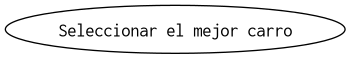

In [3]:
# A continuación se define la capa superior (Nivel 1) donde se indica el OBJETIVO del árbol

# Nivel 1: Objetivo principal
dot.node('A', 'Seleccionar el mejor carro')

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

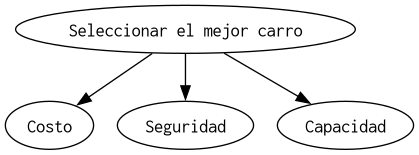

In [4]:
# A continuación se define la siguiente capa (Nivel 2) donde se indican los CRITERIOS del árbol

# Nivel 2: Criterios
dot.node('B', 'Costo')
dot.node('C', 'Seguridad')
dot.node('D', 'Capacidad')

# Enlaces (Del nodo A del Nivel 1 se definen enlaces para cada uno de los nodos del Nivel 2)
dot.edges(['AB', 'AC', 'AD'])

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

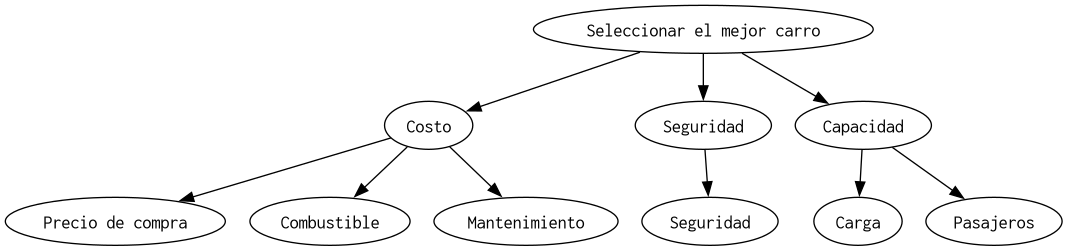

In [5]:
# A continuación se define la siguiente capa (Nivel 3) donde se indican los SUBCRITERIOS del árbol

# Nivel 3: Subcriterios
dot.node('E', 'Precio de compra')
dot.node('F', 'Combustible')
dot.node('G', 'Mantenimiento')
dot.node('H', 'Seguridad')
dot.node('I', 'Carga')
dot.node('J', 'Pasajeros')

# Enlaces (De los nodos del Nivel 2 se definen enlaces para cada uno de los nodos del Nivel 3)
dot.edges(['BE', 'BF', 'BG', 'CH', 'DI', 'DJ'])

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

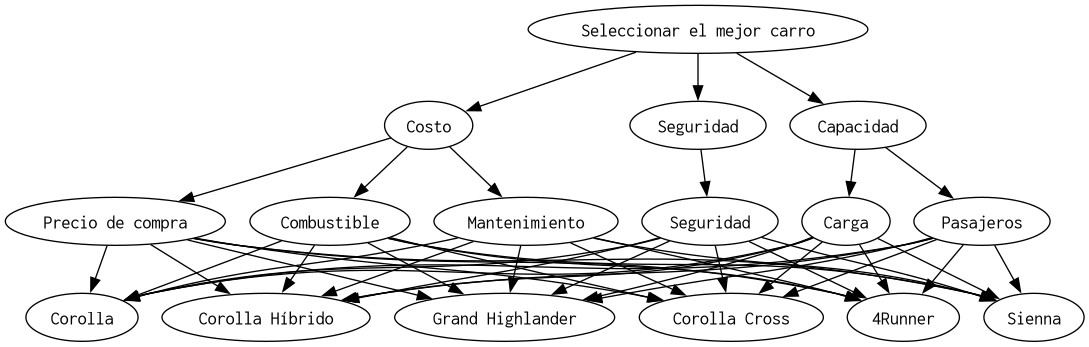

In [6]:
# Ahora se define la siguiente capa (Nivel 4) donde se indican las ALTERNATIVAS del árbol

# Nivel 4: Alternativas
dot.node('K', 'Corolla')
dot.node('L', 'Corolla Híbrido')
dot.node('M', 'Grand Highlander')
dot.node('N', 'Corolla Cross')
dot.node('O', '4Runner')
dot.node('P', 'Sienna')

# Enlaces (De los nodos del Nivel 3 se definen enlaces para cada uno de los nodos del Nivel 4)
dot.edges(['EK', 'EL', 'EM','EN', 'EO', 'EP',
           'FK', 'FL', 'FM', 'FN', 'FO', 'FP',
           'GK', 'GL', 'GM', 'GN', 'GO', 'GP',
           'HK', 'HL', 'HM', 'HN', 'HO', 'HP',
           'IK', 'IL', 'IM', 'IN', 'IO', 'IP',
           'JK', 'JL', 'JM', 'JN', 'JO', 'JP'])

# Renderizar el gráfico
dot.render('/content/AHP_hierarchy', format='png', view=False)

# Mostrar el gráfico en el cuaderno
Image('/content/AHP_hierarchy.png')

## **Paso 2: Calcular los pesos de los criterios locales**

In [7]:
# Se importa la librería numpy para realizar cálculos matemáticos
import numpy as np
# Se importa la librería pandas para manipular tablas
import pandas as pd

**Comparaciones pareadas nivel 1 (Costo, Seguridad, Capacidad)**

Las comparaciones que asigné (fila respecto a columna) están más abajo, en `matriz_Criterios`.

In [8]:
# El vector propio (pesos de los criterios) se encuentra el siguiente procedimiento
# Este procedimiento recibe como entrada la matriz de comparaciones
# Este procedimiento entrega como resultado los pesos y el máximo valor propio

def calcular_pesos(matriz):
    eigenvalues, eigenvectors = np.linalg.eig(matriz)
    max_eigenvalue = np.max(eigenvalues).real
    index = np.argmax(eigenvalues).real
    pesos = eigenvectors[:, index].real
    pesos = pesos / pesos.sum()
    return pesos, max_eigenvalue

### %RELLENAR% En matriz_Criterios ponga sus pesos

Sigo con el mismo perfil del taller anterior. El carro es para moverme con mi familia, así que lo que más me importa es lo que cuesta y después la seguridad. La capacidad me importa menos. En ese taller le di 50 % al costo, 30 % a la seguridad y 20 % a la capacidad. Aquí no pongo pesos directos sino juicios en la escala de Saaty:

1.   Costo frente a Seguridad = 2 (entre igual y apenas más importante). El costo pesa un poco más, pero no mucho, porque en el carro va mi familia. Con los pesos del taller anterior la relación era 50/30, más o menos 1,7, y lo más cercano en la escala es 2.
2.   Costo frente a Capacidad = 3 (apenas más importante). La relación anterior era 50/20 = 2,5. La subo a 3 porque si el carro no me alcanza en precio, el espacio no me sirve de nada.
3.   Seguridad frente a Capacidad = 2. La relación anterior era 30/20 = 1,5.

Las celdas debajo de la diagonal son los recíprocos. La matriz no es perfectamente consistente: si Costo vale 2 veces Seguridad y Seguridad 2 veces Capacidad, Costo debería valer 4 veces Capacidad y yo puse 3. Por eso más abajo reviso el CR.

In [9]:
# Orden de filas y columnas: Costo, Seguridad, Capacidad
matriz_Criterios = np.array([ [1  , 2,   3],
                              [1/2, 1,   2],
                              [1/3, 1/2, 1]])

### Representación gráfica de la matriz de comparaciones de los criterios

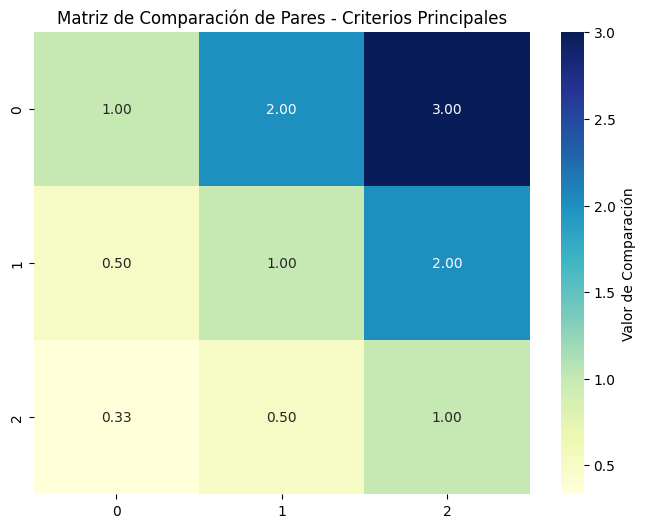

In [10]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_Criterios, annot=True, cmap='YlGnBu', fmt='.2f', cbar_kws={'label': 'Valor de Comparación'})
plt.title('Matriz de Comparación de Pares - Criterios Principales')
plt.show()

Cálculo de los pesos y del máximo de los valores propios

In [11]:
pesos_criterios, max_eigenvalueCriterios = calcular_pesos(matriz_Criterios)
print("Pesos de los criterios principales:", pesos_criterios)
print("Máximo valor propio de criterios:", max_eigenvalueCriterios)

Pesos de los criterios principales: [0.53961455 0.29696133 0.16342412]
Máximo valor propio de criterios: 3.009202712714283


#### Cálculo alternativo aproximado y simple: cálculo de pesos por normalización de columnas

El procedimiento `calcular_pesos` usa el **vector propio** de la matriz de comparaciones (método exacto de Saaty). En clase se presenta un método aproximado y muy intuitivo: **normalizar cada columna** (dividir por su suma) y luego **promediar por filas**. Ambos métodos deben dar pesos muy parecidos cuando la matriz es consistente. A continuación se implementa el método de la clase y se compara con el del vector propio, sin modificar nada de lo anterior.


In [12]:
# Metodo de la clase: normalizar por columnas y promediar por filas
# (Se agrega como complemento; no reemplaza a calcular_pesos)
def pesos_normalizacion_columnas(matriz):
    matriz = np.array(matriz, dtype=float)
    # Se normaliza cada columna dividiendola por la suma de la columna
    columnas_normalizadas = matriz / matriz.sum(axis=0)
    # El peso de cada criterio es el promedio de su fila normalizada
    pesos = columnas_normalizadas.mean(axis=1)
    return pesos

pesos_criterios_colnorm = pesos_normalizacion_columnas(matriz_Criterios)

print("Pesos por vector propio (calcular_pesos):", np.round(pesos_criterios, 4))
print("Pesos por normalizacion de columnas    :", np.round(pesos_criterios_colnorm, 4))
print("Diferencia maxima entre ambos metodos  :",
      np.round(np.abs(pesos_criterios - pesos_criterios_colnorm).max(), 5))


Pesos por vector propio (calcular_pesos): [0.5396 0.297  0.1634]
Pesos por normalizacion de columnas    : [0.539  0.2973 0.1638]
Diferencia maxima entre ambos metodos  : 0.00065


## **Paso 3: Cálculo del índice de consistencia**

El Índice de Consistencia (CI) se calcula con la fórmula:

$$\text{CI} = \frac{\lambda_{\text{max}} - n}{n - 1}$$

donde $n$ es el tamaño de la matriz.

La Razón de Consistencia (CR) se calcula como:

$$\text{CR} = \frac{\text{CI}}{\text{RI}}$$

donde $\text{RI}$ es el Índice Aleatorio correspondiente al tamaño de la matriz. Los valores de RI para diferentes tamaños de matrices son:

$$
\text{RI}_{n} = \begin{cases}
0.00 & \text{si } n = 1 \text{ o } 2 \\
0.58 & \text{si } n = 3 \\
0.90 & \text{si } n = 4 \\
1.12 & \text{si } n = 5 \\
1.24 & \text{si } n = 6 \\
\vdots
\end{cases}
$$

La razón de consistencia debe ser menor a 0,1 para que los resultados sean coherentes. En una matriz de orden 2 no es necesario calcular la razón de consistencia.

**Nota adicional:**
Saaty obtuvo los valores del Índice Aleatorio (RI) mediante un experimento de simulación matemática por computadora, simulando (con muchísimas iteraciones) qué pasaría si alguien respondiera a la matriz de comparaciones de forma completamente al azar. Esto lo hizo para diferentes tamaños de matrices.

El índice aleatorio es el promedio de los Índices de Consistencia (CI) de cada una de esas miles de matrices aleatorias.

CR= CI /RI, significa que tan cerca esta la matriz dada, de una al azar

Si  CR= 1.0, las respuestas dadas  son indistinguibles de respuestas generadas al azar.

Saaty estableció un límite empírico razonable de 0.10 para aceptar las respuestas como válidas.


In [13]:
# El índice de consistencia se calcula con el siguiente procedimiento

# Este procedimiento recibe como entrada la matriz de comparaciones y el máximo valor propio
# Este procedimiento entrega como resultado el índice de consistencia

def indice_inconsistencia(matriz, max_eigenvalue):
    n = matriz.shape[0]
    CI = (max_eigenvalue - n) / (n - 1)
    return CI

# Este procedimiento recibe como entrada el índice de consistencia (CI) y el índice aleatorio (RI)
# Este procedimiento entrega como resultado la razón de consistencia (CR)



# Siguiendo los de excel (valores de Alonso-Lamata)
def razon_consistencia(CI, RI):
    CR = CI / RI
    RI_values = {
    1: 0.00, 2: 0.00, 3: 0.525, 4: 0.882, 5: 1.115,
    6: 1.252 ,7: 1.341, 8: 1.404, 9: 1.452, 10: 1.484
    }
    return CR

In [14]:
IndiceConsistencia_Criterios = indice_inconsistencia(matriz_Criterios, max_eigenvalueCriterios)
print("Índice de Consistencia de Criterios:", IndiceConsistencia_Criterios)

# Recuerde actualizar el valor de RI (índice aleatorio, random index)
RazonCosistencia_Criterios = razon_consistencia(IndiceConsistencia_Criterios, 0.58)    #0.58 por ser matriz de tamaño 3
print("Razón de Consistencia de Criterios:", RazonCosistencia_Criterios)

Índice de Consistencia de Criterios: 0.004601356357141428
Razón de Consistencia de Criterios: 0.007933373029554188


## **Paso 4: Calcular los pesos locales de los subcriterios**

Para los subcriterios seguí la misma idea.

**Costo** (orden: Precio de compra, Combustible, Mantenimiento)

1. Precio frente a Combustible = 2. El precio se paga de una vez y es el que define si puedo comprar el carro o no. El combustible se va pagando y pesa un poco menos.
2. Precio frente a Mantenimiento = 3. Es el gasto más pequeño de los tres: en los seis carros el mantenimiento a cinco años está entre 1.645 y 2.294 USD.
3. Combustible frente a Mantenimiento = 2. En los seis carros el gasto de combustible a cinco años es mayor que el de mantenimiento.

En el taller anterior el reparto dentro del costo era 50-30-20, el mismo del nivel principal, por eso esta matriz me quedó igual a `matriz_Criterios`.

**Capacidad** (orden: Carga, Pasajeros)

* Pasajeros frente a Carga = 2. Para un carro familiar me importan más los puestos que el baúl. Antes la relación era 60/40 = 1,5, y lo más cercano en la escala es 2.

**Seguridad** tiene un solo hijo, entonces no necesita matriz.

### %RELLENAR% en matriz_Costo y matriz_Capacidad, ponga sus pesos.

In [15]:
# Orden: Precio de compra, Combustible, Mantenimiento
matriz_Costo    = np.array([[1  , 2  , 3],
                            [1/2, 1  , 2],
                            [1/3, 1/2, 1]])

pesos_Costo, max_eigenvalueCosto = calcular_pesos(matriz_Costo)
print("Pesos de los subcriterios de costo:", pesos_Costo)

print("Pesos de los subcriterios de seguridad:", pesos_criterios[1] )  #no tiene sino un hijo, no necesita matriz de comparacion

# Orden: Carga, Pasajeros
matriz_Capacidad  = np.array([[1  , 1/2],
                              [2  , 1]])

pesos_Capacidad, max_eigenvalueCapacidad = calcular_pesos(matriz_Capacidad)
print("Pesos de los subcriterios de capacidad:", pesos_Capacidad)

Pesos de los subcriterios de costo: [0.53961455 0.29696133 0.16342412]
Pesos de los subcriterios de seguridad: 0.2969613312124973
Pesos de los subcriterios de capacidad: [0.33333333 0.66666667]


## **Paso 5: Calcular los pesos globales de los subcriterios**

Los pesos globales de un nodo del árbol se calculan mediante la multiplicacion de todos los pesos que están en niveles superiores a ese nodo

In [16]:
Peso_Precio        = pesos_criterios[0] * pesos_Costo[0]
Peso_Combustible   = pesos_criterios[0] * pesos_Costo[1]
Peso_Mantenimiento = pesos_criterios[0] * pesos_Costo[2]
Peso_Seguridad     = pesos_criterios[1]
Peso_Carga         = pesos_criterios[2] * pesos_Capacidad[0]
Peso_Pasajeros     = pesos_criterios[2] * pesos_Capacidad[1]

vector_pesos_globales = np.array([Peso_Precio,
                                  Peso_Combustible,
                                  Peso_Mantenimiento,
                                  Peso_Seguridad,
                                  Peso_Carga,
                                  Peso_Pasajeros
                                  ])

print("Peso global del subcriterio Precio de compra:", Peso_Precio)
print("Peso global del subcriterio Combustible:", Peso_Combustible)
print("Peso global del subcriterio Mantenimiento:", Peso_Mantenimiento)
print("Peso global del subcriterio Seguridad:", Peso_Seguridad)
print("Peso global del subcriterio Carga:", Peso_Carga)
print("Peso global del subcriterio Pasajeros:", Peso_Pasajeros)

print("Vector de pesos globales:", vector_pesos_globales)
print("Suma de los pesos globales:", vector_pesos_globales.sum())

Peso global del subcriterio Precio de compra: 0.2911838628102929
Peso global del subcriterio Combustible: 0.16024465517528336
Peso global del subcriterio Mantenimiento: 0.08818603223549862
Peso global del subcriterio Seguridad: 0.2969613312124973
Peso global del subcriterio Carga: 0.05447470618880933
Peso global del subcriterio Pasajeros: 0.10894941237761863
Vector de pesos globales: [0.29118386 0.16024466 0.08818603 0.29696133 0.05447471 0.10894941]
Suma de los pesos globales: 1.0000000000000002


## **Paso 6: Primera normalización de la matriz de consecuencias**

Se multiplica por -1 los criterios a minimizar y, los valores se llevan a una escala 0-1 para cada criterio (0 para el peor valor, 1 para el mejor valor de cada criterio)

In [17]:
# Crear el DataFrame con los datos de la matriz de consecuencias
# Son los mismos seis Toyota 2026 del taller de programación de compromiso

# Matriz de consecuencias (los criterios a minimizar van con signo negativo)
data = [
    [-24320, -26170, -43355, -26485, -43365, -41915],      # C1=Precio de compra (USD)
    [-4365, -3126, -6550, -4864, -6945, -4306],            # C2=Combustible (USD en 5 años, KBB)
    [-1780, -2294, -2219, -1831, -1723, -1645],            # C3=Mantenimiento (USD en 5 años, KBB)
    [5, 5, 5, 5, 4, 5],                                    # C4=Seguridad (estrellas NHTSA, 1 a 5)
    [13.1, 13.1, 20.6, 24.0, 48.4, 33.5],                  # C5=Carga (pies cúbicos con todas las plazas en uso)
    [5, 5, 8, 5, 5, 8],                                    # C6=Pasajeros (cantidad)

]

criterios = ['Precio de compra', 'Combustible', 'Mantenimiento', 'Seguridad', 'Carga', 'Pasajeros']
#
# Nombres de las alternativas
alternativas = ['Corolla', 'Corolla Híbrido', 'Grand Highlander', 'Corolla Cross', '4Runner',
           'Sienna']

# Crear el DataFrame
matriz_consecuencias = pd.DataFrame(data, index=criterios, columns=alternativas)

# Mostrar el DataFrame
print(matriz_consecuencias)

                  Corolla  Corolla Híbrido  Grand Highlander  Corolla Cross  \
Precio de compra -24320.0         -26170.0          -43355.0       -26485.0   
Combustible       -4365.0          -3126.0           -6550.0        -4864.0   
Mantenimiento     -1780.0          -2294.0           -2219.0        -1831.0   
Seguridad             5.0              5.0               5.0            5.0   
Carga                13.1             13.1              20.6           24.0   
Pasajeros             5.0              5.0               8.0            5.0   

                  4Runner   Sienna  
Precio de compra -43365.0 -41915.0  
Combustible       -6945.0  -4306.0  
Mantenimiento     -1723.0  -1645.0  
Seguridad             4.0      5.0  
Carga                48.4     33.5  
Pasajeros             5.0      8.0  


Se realiza la normalización de cada valor $Z_{ij}$ que corresponde al criterio $i$ en la alternativa $j$ mediante la siguiente expresión:


$$
Z_{ij}^{\text{norm}} = \frac{Z_{ij} - \min(Z_i)}{\max(Z_i) - \min(Z_i)}
$$

## **Paso 7: Segunda normalización de la matriz de consecuencias**

Para seguir la formalización del método AHP,  cada nodo padre debe repartir una unidad entre los nodos hijos: cada nodo criterio de ultimo nivel, debe repartir una unidad entre las alternativas.

In [18]:
# Normalización por filas usando min-max
matriz_normalizada = matriz_consecuencias.apply(lambda fila: (fila - fila.min()) / (fila.max() - fila.min()), axis=1)

print("Matriz normalizada por filas (min-max):")
print(matriz_normalizada.round(3))


Matriz normalizada por filas (min-max):
                  Corolla  Corolla Híbrido  Grand Highlander  Corolla Cross  \
Precio de compra    1.000            0.903             0.001          0.886   
Combustible         0.676            1.000             0.103          0.545   
Mantenimiento       0.792            0.000             0.116          0.713   
Seguridad           1.000            1.000             1.000          1.000   
Carga               0.000            0.000             0.212          0.309   
Pasajeros           0.000            0.000             1.000          0.000   

                  4Runner  Sienna  
Precio de compra     0.00   0.076  
Combustible          0.00   0.691  
Mantenimiento        0.88   1.000  
Seguridad            0.00   1.000  
Carga                1.00   0.578  
Pasajeros            0.00   1.000  


In [19]:
# Normalización por filas (cada fila se divide por la suma de esa fila)
matriz_2normalizada = matriz_normalizada.div(matriz_normalizada.sum(axis=1), axis=0)

print("Matriz normalizada por filas:")
print(matriz_2normalizada.round(3))


Matriz normalizada por filas:
                  Corolla  Corolla Híbrido  Grand Highlander  Corolla Cross  \
Precio de compra    0.349            0.315             0.000          0.309   
Combustible         0.224            0.332             0.034          0.181   
Mantenimiento       0.226            0.000             0.033          0.204   
Seguridad           0.200            0.200             0.200          0.200   
Carga               0.000            0.000             0.101          0.147   
Pasajeros           0.000            0.000             0.500          0.000   

                  4Runner  Sienna  
Precio de compra    0.000   0.027  
Combustible         0.000   0.229  
Mantenimiento       0.251   0.286  
Seguridad           0.000   0.200  
Carga               0.476   0.275  
Pasajeros           0.000   0.500  


In [20]:
# verificamos estar normalizando correctamente
for index, row in matriz_2normalizada.iterrows():
    row_sum = row.sum()
    print(f"La fila '{index}' suma: {row_sum:.6f}")

La fila 'Precio de compra' suma: 1.000000
La fila 'Combustible' suma: 1.000000
La fila 'Mantenimiento' suma: 1.000000
La fila 'Seguridad' suma: 1.000000
La fila 'Carga' suma: 1.000000
La fila 'Pasajeros' suma: 1.000000


## **Paso 8: Ponderar los pesos globales (de criterios de último nivel) con los valores de la matriz de consecuencias doblemente normalizada**

In [21]:
matriz_ponderada = matriz_2normalizada.mul(vector_pesos_globales, axis=0)

print("Matriz ponderada:")
print(matriz_ponderada.round(4))

Matriz ponderada:
                  Corolla  Corolla Híbrido  Grand Highlander  Corolla Cross  \
Precio de compra   0.1016           0.0917            0.0001         0.0901   
Combustible        0.0359           0.0532            0.0055         0.0290   
Mantenimiento      0.0200           0.0000            0.0029         0.0180   
Seguridad          0.0594           0.0594            0.0594         0.0594   
Carga              0.0000           0.0000            0.0055         0.0080   
Pasajeros          0.0000           0.0000            0.0545         0.0000   

                  4Runner  Sienna  
Precio de compra   0.0000  0.0077  
Combustible        0.0000  0.0367  
Mantenimiento      0.0222  0.0252  
Seguridad          0.0000  0.0594  
Carga              0.0260  0.0150  
Pasajeros          0.0000  0.0545  


In [22]:
puntajes_totales = matriz_ponderada.sum(axis=0)

print("Puntaje total por carro:")
print(puntajes_totales.round(4))

Puntaje total por carro:
Corolla             0.2169
Corolla Híbrido     0.2043
Grand Highlander    0.1278
Corolla Cross       0.2044
4Runner             0.0481
Sienna              0.1985
dtype: float64


In [23]:
mejor_carro = puntajes_totales.idxmax()
mejor_valor = puntajes_totales.max()

print(f"El mejor carro es {mejor_carro} con un puntaje de {mejor_valor:.4f}")

El mejor carro es Corolla con un puntaje de 0.2169


### Resumen de resultados del Taller 1

Se consolidan los puntajes AHP y la jerarquía final en una sola tabla para facilitar la lectura de la decisión.


In [24]:
# Tabla resumen: puntaje AHP y jerarquia por carro
resumen_AHP = pd.DataFrame({"Puntaje AHP": puntajes_totales.round(4)})
resumen_AHP["Jerarquia"] = resumen_AHP["Puntaje AHP"].rank(ascending=False).astype(int)
resumen_AHP = resumen_AHP.sort_values("Jerarquia")

print("Resumen final del Taller 1 (1 = mejor):")
print(resumen_AHP)
print(f"\nDecision: el mejor carro es {mejor_carro} con puntaje {mejor_valor:.4f}.")

segundo_carro = resumen_AHP.index[1]
diferencia = mejor_valor - resumen_AHP["Puntaje AHP"].iloc[1]
print(f"Diferencia con el segundo ({segundo_carro}): {diferencia:.4f}")

Resumen final del Taller 1 (1 = mejor):
                  Puntaje AHP  Jerarquia
Corolla                0.2169          1
Corolla Cross          0.2044          2
Corolla Híbrido        0.2043          3
Sienna                 0.1985          4
Grand Highlander       0.1278          5
4Runner                0.0481          6

Decision: el mejor carro es Corolla con puntaje 0.2169.
Diferencia con el segundo (Corolla Cross): 0.0125


### Análisis de la jerarquía y elección del carro

| Jerarquía | Carro | Puntaje AHP |
|:---:|---|:---:|
| 1 | Corolla | 0,2169 |
| 2 | Corolla Cross | 0,2044 |
| 3 | Corolla Híbrido | 0,2043 |
| 4 | Sienna | 0,1985 |
| 5 | Grand Highlander | 0,1278 |
| 6 | 4Runner | 0,0481 |

Con mis juicios gana el **Corolla** con 0,2169. Le saca 0,0125 al Corolla Cross, que queda segundo casi empatado con el Corolla Híbrido (0,2044 contra 0,2043). El Sienna queda cuarto.

El Corolla gana porque es el más barato (24.320 USD) y el precio es el subcriterio con más peso global (0,2912). También le va bien en combustible y mantenimiento, y tiene cinco estrellas. Sus puntos débiles son la carga (13,1 pies cúbicos, la menor junto con el Corolla Híbrido) y los pasajeros (cinco), pero esos dos subcriterios juntos pesan 0,1634, que es el peso de Capacidad.

El Sienna es el más completo. Es el que menos gasta en mantenimiento, tiene ocho puestos y cinco estrellas, y es segundo en combustible y en carga. Lo que lo baja es el precio (41.915 USD): después de la segunda normalización solo recibe 0,027 en el subcriterio que más pesa.

El 4Runner queda último porque es el único con cuatro estrellas, y eso le da cero en seguridad, que pesa 0,2970. Además es el más caro y el que más gasta en combustible. El Grand Highlander queda quinto: cuesta casi lo mismo que el 4Runner y el Sienna es igual o mejor que él en todos los criterios (en el taller anterior ya había salido como alternativa dominada).

**Elección:** me quedo con el **Corolla**. Es el mismo carro que elegí en el taller de programación de compromiso con mis pesos, así que los dos métodos llegan a lo mismo. Como la diferencia con los que siguen es pequeña, más abajo reviso qué tan estable es este resultado.

## **Informes gráficos**

**Pesos por Criterio y Pesos por Subcriterio**

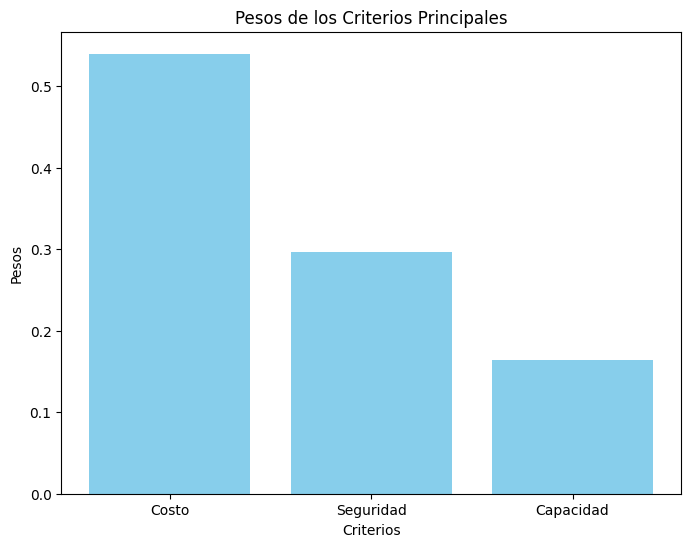

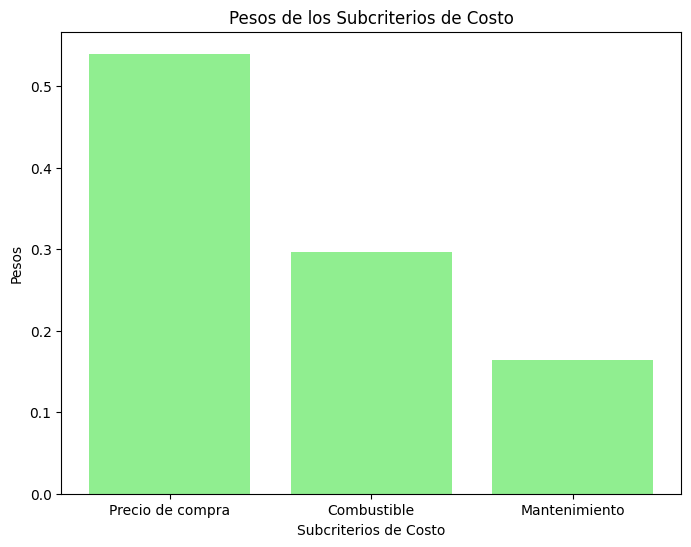

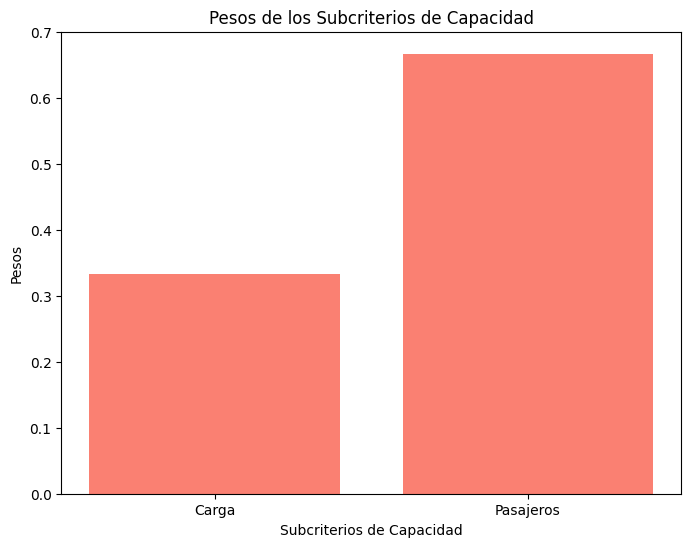

In [25]:
import matplotlib.pyplot as plt

# Gráfico de barras para los pesos de los criterios principales
plt.figure(figsize=(8, 6))
plt.bar(['Costo', 'Seguridad', 'Capacidad'], pesos_criterios, color='skyblue')
plt.xlabel('Criterios')
plt.ylabel('Pesos')
plt.title('Pesos de los Criterios Principales')
plt.show()

# Gráfico de barras para los pesos de los subcriterios de Costo
plt.figure(figsize=(8, 6))
plt.bar(['Precio de compra', 'Combustible','Mantenimiento'], pesos_Costo, color='lightgreen')
plt.xlabel('Subcriterios de Costo')
plt.ylabel('Pesos')
plt.title('Pesos de los Subcriterios de Costo')
plt.show()

# Gráfico de barras para los pesos de los subcriterios de Capacidad
plt.figure(figsize=(8, 6))
plt.bar(['Carga', 'Pasajeros'], pesos_Capacidad, color='salmon')
plt.xlabel('Subcriterios de Capacidad')
plt.ylabel('Pesos')
plt.title('Pesos de los Subcriterios de Capacidad')
plt.show()

**Puntaje de las Alternativas**

/tmp/ipykernel_7/3345238999.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=alternativas, y = puntajes_totales, palette='muted')


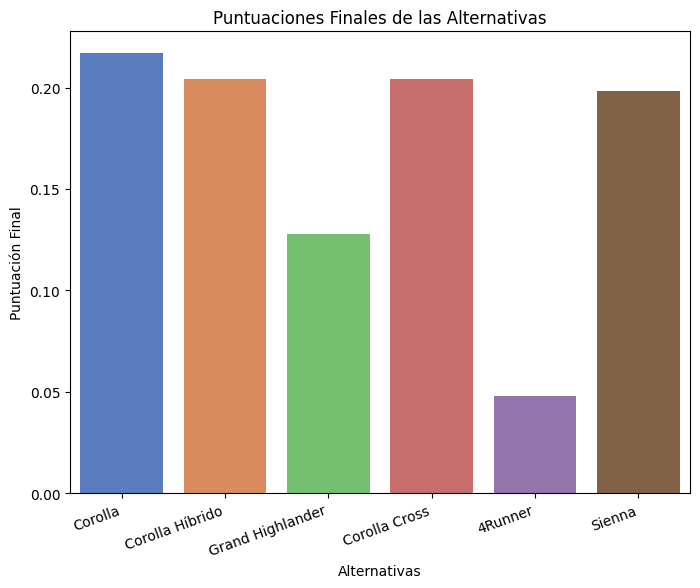

In [26]:
plt.figure(figsize=(8, 6))
sns.barplot(x=alternativas, y = puntajes_totales, palette='muted')
plt.title('Puntuaciones Finales de las Alternativas')
plt.xlabel('Alternativas')
plt.ylabel('Puntuación Final')
plt.xticks(rotation=20, ha='right')
plt.show()

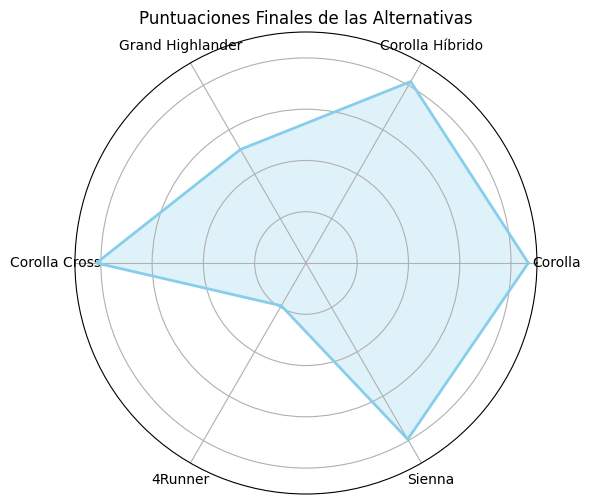

In [27]:
# Graficar los puntajes de las alternativas
def plot_alternatives(weights, labels, title):
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    weights = np.concatenate((weights, [weights[0]]))
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.fill(angles, weights, color='skyblue', alpha=0.25)
    ax.plot(angles, weights, color='skyblue', linewidth=2)
    ax.set_yticklabels([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    plt.title(title)
    plt.show()

plot_alternatives(puntajes_totales.values, alternativas, "Puntuaciones Finales de las Alternativas")

# Adicion - Consistencia de los juicios y análisis de sensibilidad

*Continuación del Taller 1. Se profundiza en la medición de la consistencia de las matrices de comparación pareada y en la robustez de la decisión mediante simulación de Montecarlo.*


## Índice y razón de consistencia (CR)

### Idea central

La **consistencia** de los juicios se relaciona con la **transitividad** de las preferencias. Por ejemplo, si el criterio $A$ es el doble de importante que $B$, y $B$ el doble que $C$, la consistencia cardinal perfecta exige que $A$ se juzgue **4 veces** más importante que $C$. Como los juicios humanos rara vez son perfectos, Saaty definió la **Razón de Consistencia (CR)**, que mide cuánto se alejan los juicios de la consistencia perfecta:

$$\text{CR} = \frac{\text{IC}}{\text{IA}} \qquad \text{Si } \text{CR} \le 0.10 \Rightarrow \text{consistencia aceptable}$$

donde **IC** es el *índice de consistencia* (depende del autovalor máximo $\lambda_{max}$ y del tamaño $N$ de la matriz) e **IA** es el *índice aleatorio* (valor de referencia de una matriz llenada al azar).

### Cálculo de $\lambda_{max}$ (método manual de Saaty)

Para cada matriz de comparaciones $[A]$ con vector de pesos $[B]$:

1. Multiplicar $[A]\,[B] = [C]$ (nuevo vector).
2. Dividir cada elemento de $[C]$ por su correspondiente en $[B]$, obteniendo $[D]$.
3. $\lambda_{max} = $ promedio de los elementos de $[D]$.

### Fórmulas

$$\text{IC} = \frac{\lambda_{max} - N}{N - 1} \qquad\qquad \text{CR} = \frac{\text{IC}}{\text{IA}}$$

**Índice aleatorio IA** (aproximado por Saaty con muchos ensayos) (RI - Random Index):

| N  | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|----|---|---|-----|-----|-----|-----|-----|-----|-----|-----|
| IA | 0 | 0 | 0.58| 0.90| 1.12| 1.24| 1.32| 1.41| 1.45| 1.49|

### ¿Por qué funciona?

Si los juicios fueran perfectamente consistentes, existirían pesos $w_i$ tales que $a_{ij} = w_i / w_j$. En ese caso se cumple $A\,w = \lambda_{max}\,w$ con $\lambda_{max} = N$, y $(Aw)_i / w_i$ es constante. **Cuanto más se aleja $\lambda_{max}$ de $N$, más inconsistente es el juicio.** Por eso IC crece con $(\lambda_{max}-N)$.


In [28]:
# Complemento del Taller 2: funciones para analizar la consistencia de cualquier matriz.
# Se agregan con nombres nuevos para NO alterar indice_inconsistencia ni razon_consistencia.

# Indice aleatorio (IA) de Saaty segun el tamano N de la matriz
IA_SAATY = {1: 0.00, 2: 0.00, 3: 0.58, 4: 0.90, 5: 1.12,
            6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}

def lambda_max_manual(matriz, pesos):
    """Autovalor maximo por el metodo manual de Saaty:
       [C] = [A][B];  [D] = [C]/[B];  lambda_max = promedio de [D]."""
    matriz = np.array(matriz, dtype=float)
    pesos = np.array(pesos, dtype=float)
    C = matriz @ pesos          # paso 1: A * w
    D = C / pesos               # paso 2: division elemento a elemento
    return D.mean()             # paso 3: promedio

def analizar_consistencia(matriz, nombre=""):
    """Calcula pesos, lambda_max (manual), IC, IA y CR de una matriz de comparaciones.
       Devuelve un diccionario con el resumen e imprime el veredicto."""
    matriz = np.array(matriz, dtype=float)
    N = matriz.shape[0]
    # Se reutiliza calcular_pesos (vector propio) definido en el Taller 1
    pesos, _ = calcular_pesos(matriz)
    lmax = lambda_max_manual(matriz, pesos)
    IC = (lmax - N) / (N - 1) if N > 1 else 0.0
    IA = IA_SAATY.get(N, np.nan)
    CR = IC / IA if IA and IA > 0 else 0.0   # para N<=2, IA=0 => CR no aplica
    if N <= 2:
        veredicto = "N<=2: la comparacion es siempre consistente (no se calcula CR)."
    else:
        veredicto = "Consistencia ACEPTABLE (CR<=0.10)" if CR <= 0.10 else "INCONSISTENTE (CR>0.10): revisar juicios"
    print(f"[{nombre}]  N={N}  lambda_max={lmax:.4f}  IC={IC:.4f}  IA={IA}  CR={CR:.4f}  -> {veredicto}")
    return {"nombre": nombre, "N": N, "lambda_max": lmax, "IC": IC, "IA": IA, "CR": CR}


### Ejemplo (matriz $5\times5$)

Se reproduce el ejemplo del material de clase, cuya matriz de orden 5 arroja $\lambda_{max}\approx 5.31$, $\text{IC}\approx 0.08$ y $\text{CR}\approx 0.07 < 0.10$, por lo que **se acepta el nivel de inconsistencia**.


In [29]:
# Matriz 5x5 del ejemplo de clase
matriz_ejemplo = np.array([
    [1,    1/3, 5,   6,   5  ],
    [3,    1,   6,   7,   6  ],
    [1/5,  1/6, 1,   3,   1  ],
    [1/6,  1/7, 1/3, 1,   1/4],
    [1/5,  1/6, 1,   4,   1  ],
])

res_ejemplo = analizar_consistencia(matriz_ejemplo, "Ejemplo clase 5x5")

# Verificacion cruzada con el autovalor de numpy (numpy.linalg.eig) (metodo del vector propio)
_, lmax_numpy = calcular_pesos(matriz_ejemplo)
print(f"\nVerificacion: lambda_max por numpy.linalg.eig = {lmax_numpy:.4f}")
print("Ambos metodos (manual y vector propio) deben coincidir aproximadamente.")


[Ejemplo clase 5x5]  N=5  lambda_max=5.3029  IC=0.0757  IA=1.12  CR=0.0676  -> Consistencia ACEPTABLE (CR<=0.10)

Verificacion: lambda_max por numpy.linalg.eig = 5.3029
Ambos metodos (manual y vector propio) deben coincidir aproximadamente.


### Aplicación a las matrices del Taller 1

Se evalúa la consistencia de todas las matrices de comparación pareada usadas en el caso del carro. Se reutilizan directamente las matrices ya definidas .

In [30]:
# Se analizan las tres matrices pareadas del caso del carro.
# La de Capacidad es de tamaño 2: analizar_consistencia avisa que siempre es consistente.
matrices_taller1 = {
    "Criterios (Costo/Seguridad/Capacidad)": matriz_Criterios,
    "Subcriterio Costo":    matriz_Costo,
    "Subcriterio Capacidad": matriz_Capacidad,
   }

resultados_consistencia = [analizar_consistencia(m, nombre) for nombre, m in matrices_taller1.items()]

# Tabla resumen
tabla_CR = pd.DataFrame(resultados_consistencia)[["nombre", "N", "lambda_max", "IC", "IA", "CR"]]
print("\nResumen de consistencia:")
print(tabla_CR.round(4).to_string(index=False))

[Criterios (Costo/Seguridad/Capacidad)]  N=3  lambda_max=3.0092  IC=0.0046  IA=0.58  CR=0.0079  -> Consistencia ACEPTABLE (CR<=0.10)
[Subcriterio Costo]  N=3  lambda_max=3.0092  IC=0.0046  IA=0.58  CR=0.0079  -> Consistencia ACEPTABLE (CR<=0.10)
[Subcriterio Capacidad]  N=2  lambda_max=2.0000  IC=0.0000  IA=0.0  CR=0.0000  -> N<=2: la comparacion es siempre consistente (no se calcula CR).

Resumen de consistencia:
                               nombre  N  lambda_max     IC   IA     CR
Criterios (Costo/Seguridad/Capacidad)  3      3.0092 0.0046 0.58 0.0079
                    Subcriterio Costo  3      3.0092 0.0046 0.58 0.0079
                Subcriterio Capacidad  2      2.0000 0.0000 0.00 0.0000


**Resultado de la consistencia de mis matrices**

* Criterios (Costo/Seguridad/Capacidad): λmax = 3,0092, IC = 0,0046 y CR = 0,0079.
* Subcriterios de Costo: los mismos valores, porque la matriz es igual.
* Subcriterios de Capacidad: es de 2×2, así que siempre es consistente (λmax = 2 y CR = 0).

Las tres cumplen CR ≤ 0,10, por eso no tuve que ajustar ningún juicio. La pequeña inconsistencia de las matrices de 3×3 viene del 3 que puse donde la transitividad pedía 4. El valor coincide con el del Paso 3, donde `razon_consistencia` también da 0,0079 para la matriz de criterios.

### Demostración de consistencia perfecta

Si conocemos de antemano los pesos $w = [0.5,\ 0.3,\ 0.2]$ y construimos la matriz "ideal" con $a_{ij} = w_i/w_j$, el resultado debe ser $\lambda_{max}=N=3$, $\text{IC}=0$ y $\text{CR}=0$: **consistencia perfecta**.


In [31]:
# Se construye una matriz perfectamente consistente a partir de pesos conocidos
w_ideal = np.array([0.5, 0.3, 0.2])
matriz_ideal = np.array([[w_ideal[i] / w_ideal[j] for j in range(3)] for i in range(3)])

print("Matriz ideal (a_ij = w_i / w_j):")
print(np.round(matriz_ideal, 3))
print()

# Analizar la consistencia y capturar el resultado
res_ideal = analizar_consistencia(matriz_ideal, "Matriz perfectamente consistente")

print("\nDetalles de consistencia de la matriz ideal:")
print(f"  N: {res_ideal['N']}")
print(f"  Lambda Max: {res_ideal['lambda_max']:.4f}")
print(f"  IC (Índice de Consistencia): {res_ideal['IC']:.4f}")
print(f"  IA (Índice Aleatorio): {res_ideal['IA']}")
print(f"  CR (Razón de Consistencia): {res_ideal['CR']:.4f}")

if res_ideal['CR'] == 0:
    print("\nConclusión: La matriz es perfectamente consistente (CR=0) ya que fue construida a partir de pesos ideales.")
else:
    print(f"\nConclusión: La matriz tiene un CR de {res_ideal['CR']:.4f}.")


Matriz ideal (a_ij = w_i / w_j):
[[1.    1.667 2.5  ]
 [0.6   1.    1.5  ]
 [0.4   0.667 1.   ]]

[Matriz perfectamente consistente]  N=3  lambda_max=3.0000  IC=0.0000  IA=0.58  CR=0.0000  -> Consistencia ACEPTABLE (CR<=0.10)

Detalles de consistencia de la matriz ideal:
  N: 3
  Lambda Max: 3.0000
  IC (Índice de Consistencia): 0.0000
  IA (Índice Aleatorio): 0.58
  CR (Razón de Consistencia): 0.0000

Conclusión: La matriz es perfectamente consistente (CR=0) ya que fue construida a partir de pesos ideales.


#**Análisis de sensibilidad manual**

In [32]:
import ipywidgets as widgets
from ipywidgets import interact

def calcular_puntuaciones_interactivo(peso_precio, peso_combustible, peso_mantenimiento, peso_seguridad, peso_carga, peso_pasajeros):
    # Normalizar los pesos para que sumen 1
    total = peso_precio + peso_combustible + peso_mantenimiento + peso_seguridad + peso_carga + peso_pasajeros
    peso_precio/= total
    peso_combustible/= total
    peso_mantenimiento/= total
    peso_seguridad/= total
    peso_carga/= total
    peso_pasajeros/= total

    vector_pesos_globalesN= np.array([peso_precio,
                                  peso_combustible,
                                  peso_mantenimiento,
                                  peso_seguridad,
                                  peso_carga,
                                  peso_pasajeros
                                  ])

    matriz_ponderadaN = matriz_2normalizada.mul(vector_pesos_globalesN, axis=0)

    puntuaciones_finales = matriz_ponderadaN.sum(axis=0)

    print("Puntaje total por carro:")
    print(puntuaciones_finales.round(4))
    # Determinar la mejor alternativa con los nuevos pesos
    mejor_alternativa = alternativas[np.argmax(puntuaciones_finales)]

    # Visualizar las puntuaciones
    plt.figure(figsize=(8, 6))
    plt.bar(alternativas, puntuaciones_finales, color='skyblue')
    plt.title('Puntuaciones Finales de las Alternativas')
    plt.ylabel('Puntuación')
    plt.xticks(rotation=20, ha='right')
    plt.show()

    print(f"Con los pesos ajustados: Precio={peso_precio:.2f}, Combustible={peso_combustible:.2f}, Mantenimiento={peso_mantenimiento:.2f}, Seguridad={peso_seguridad:.2f}, Carga={peso_carga:.2f}, Pasajeros={peso_pasajeros:.2f}")
    print("La mejor alternativa es:", mejor_alternativa)

# Crear sliders para los pesos (arrancan en los pesos globales que salieron del AHP)
peso_precio_slider = widgets.FloatSlider(value=round(Peso_Precio, 2), min=0, max=1, step=0.01, description='Peso Precio:')
peso_combustible_slider = widgets.FloatSlider(value=round(Peso_Combustible, 2), min=0, max=1, step=0.01, description='Peso combustible:')
peso_mantenimiento_slider = widgets.FloatSlider(value=round(Peso_Mantenimiento, 2), min=0, max=1, step=0.01, description='Peso mantenimiento:')
peso_seguridad_slider = widgets.FloatSlider(value=round(Peso_Seguridad, 2), min=0, max=1, step=0.01, description='Peso Seguridad:')
peso_carga_slider = widgets.FloatSlider(value=round(Peso_Carga, 2), min=0, max=1, step=0.01, description='Peso carga:')
peso_pasajeros_slider = widgets.FloatSlider(value=round(Peso_Pasajeros, 2), min=0, max=1, step=0.01, description='Peso pasajeros:')


# Crear la interfaz interactiva
interact(calcular_puntuaciones_interactivo,
         peso_precio=peso_precio_slider,
         peso_combustible=peso_combustible_slider,
         peso_mantenimiento=peso_mantenimiento_slider,
         peso_seguridad=peso_seguridad_slider,
         peso_carga=peso_carga_slider,
         peso_pasajeros=peso_pasajeros_slider);

interactive(children=(FloatSlider(value=0.29, description='Peso Precio:', max=1.0, step=0.01), FloatSlider(val…

### Sensibilidad manual sin sliders

Los sliders sirven para explorar, pero no dejan registro. Para responder la pregunta del taller muevo cada peso global un 10 % y un 20 % por encima y por debajo de su valor, vuelvo a normalizar para que los pesos sumen 1 y miro qué carro queda de primero.

In [33]:
nombres_pesos = ['Precio de compra', 'Combustible', 'Mantenimiento', 'Seguridad', 'Carga', 'Pasajeros']
cambios = [-0.20, -0.10, 0.10, 0.20]

filas = []
for i, criterio in enumerate(nombres_pesos):
    for cambio in cambios:
        pesos_nuevos = vector_pesos_globales.copy()
        pesos_nuevos[i] = pesos_nuevos[i] * (1 + cambio)
        pesos_nuevos = pesos_nuevos / pesos_nuevos.sum()

        puntajes_nuevos = matriz_2normalizada.mul(pesos_nuevos, axis=0).sum(axis=0)
        orden = puntajes_nuevos.sort_values(ascending=False)
        filas.append({'Criterio': criterio,
                      'Cambio': f'{cambio:+.0%}',
                      'Peso nuevo': round(pesos_nuevos[i], 4),
                      'Gana': orden.index[0],
                      'Puntaje': round(orden.iloc[0], 4),
                      'Segundo': orden.index[1],
                      'Puntaje segundo': round(orden.iloc[1], 4)})

tabla_sensibilidad = pd.DataFrame(filas)
print(tabla_sensibilidad.to_string(index=False))

veces_gana = (tabla_sensibilidad['Gana'] == mejor_carro).sum()
print(f"\n{mejor_carro} queda de primero en {veces_gana} de {len(tabla_sensibilidad)} escenarios")

        Criterio Cambio  Peso nuevo    Gana  Puntaje         Segundo  Puntaje segundo
Precio de compra   -20%      0.2474  Sienna   0.2092         Corolla           0.2087
Precio de compra   -10%      0.2699 Corolla   0.2129          Sienna           0.2037
Precio de compra   +10%      0.3112 Corolla   0.2206 Corolla Híbrido           0.2074
Precio de compra   +20%      0.3302 Corolla   0.2241 Corolla Híbrido           0.2104
     Combustible   -20%      0.1324 Corolla   0.2166   Corolla Cross           0.2052
     Combustible   -10%      0.1466 Corolla   0.2167   Corolla Cross           0.2048
     Combustible   +10%      0.1735 Corolla   0.2170 Corolla Híbrido           0.2063
     Combustible   +20%      0.1863 Corolla   0.2171 Corolla Híbrido           0.2082
   Mantenimiento   -20%      0.0718 Corolla   0.2167 Corolla Híbrido           0.2079
   Mantenimiento   -10%      0.0801 Corolla   0.2168 Corolla Híbrido           0.2061
   Mantenimiento   +10%      0.0962 Corolla   0.2169  

In [34]:
# ¿Cuánto hay que mover cada peso para que el ganador cambie?
# Se mueve un peso a la vez, de 1 % en 1 %, hasta un 50 % hacia abajo y hacia arriba.
limites = []
for i, criterio in enumerate(nombres_pesos):
    fila = {'Criterio': criterio}
    for sentido, nombre_col in [(-1, 'Bajando'), (1, 'Subiendo')]:
        fila[nombre_col] = 'no cambia hasta 50 %'
        for k in range(1, 51):
            pesos_nuevos = vector_pesos_globales.copy()
            pesos_nuevos[i] = pesos_nuevos[i] * (1 + sentido * k / 100)
            pesos_nuevos = pesos_nuevos / pesos_nuevos.sum()
            puntajes_nuevos = matriz_2normalizada.mul(pesos_nuevos, axis=0).sum(axis=0)
            if puntajes_nuevos.idxmax() != mejor_carro:
                fila[nombre_col] = f'{sentido * k:+d} % (gana {puntajes_nuevos.idxmax()})'
                break
    limites.append(fila)

print(f"Cambio del peso a partir del cual {mejor_carro} deja de ganar:")
print(pd.DataFrame(limites).to_string(index=False))

Cambio del peso a partir del cual Corolla deja de ganar:
        Criterio              Bajando             Subiendo
Precio de compra  -20 % (gana Sienna) no cambia hasta 50 %
     Combustible no cambia hasta 50 % no cambia hasta 50 %
   Mantenimiento no cambia hasta 50 % no cambia hasta 50 %
       Seguridad no cambia hasta 50 % no cambia hasta 50 %
           Carga no cambia hasta 50 % no cambia hasta 50 %
       Pasajeros no cambia hasta 50 %  +34 % (gana Sienna)


**¿Sigue ganando la misma alternativa?**

Sí, con cambios pequeños. Al subir o bajar cualquier peso un 10 %, el Corolla sigue de primero en todos los casos. De los 24 escenarios (±10 % y ±20 % en cada peso) gana en 23. El único que cambia es bajar el peso del precio un 20 % (de 0,2912 a 0,2474): ahí gana el Sienna, aunque por muy poco (0,2092 contra 0,2087).

La búsqueda de límites dice lo mismo. Dentro de ±50 % solo dos cambios le quitan el primer puesto al Corolla: bajar el peso del precio un 20 % o subir el de pasajeros un 34 %. En los dos casos pasa adelante el Sienna. Los pesos de combustible, mantenimiento, seguridad y carga se pueden mover hasta un 50 % hacia arriba o hacia abajo y el Corolla sigue ganando.

Entonces la elección aguanta cambios pequeños, pero depende de que el precio tenga un peso alto. El rival real es el Sienna.

## Análisis de sensibilidad por simulación de Montecarlo

Los pesos de importancia son **subjetivos** (dependen del ánimo del decisor, de su comprensión del problema, etc.). El análisis de sensibilidad verifica la **robustez** de la decisión ante cambios en esos pesos:

- Una alternativa es **más robusta** si, al cambiar los pesos, permanece en una buena jerarquía (1.º o 2.º).
- El problema es **sensible a un criterio** si, cambiando solo el peso de ese criterio, cambia fuertemente el orden de la jerarquía.

En lugar de mover los pesos a mano, la **simulación de Montecarlo** genera muchos juegos de pesos aleatorios, recalcula el puntaje AHP en cada iteración y estima la **probabilidad de que cada alternativa quede en el primer lugar**. Aquí se aplican perturbaciones aleatorias sobre los pesos globales del caso del carro (`vector_pesos_globales`) reutilizando la matriz doblemente normalizada (`matriz_2normalizada`).

In [35]:
# Simulacion de Montecarlo para el analisis de sensibilidad de los pesos
np.random.seed(42)  # reproducibilidad

N_ITER = 500
# Matriz doblemente normalizada (criterios de ultimo nivel x carros)
M = matriz_2normalizada.values           # forma: (6 criterios, 6 carros)
alternativas_mc = list(matriz_2normalizada.columns)
n_alt = M.shape[1]

# Concentracion de la distribucion Dirichlet centrada en los pesos originales:
# valores altos = pesos cercanos a los originales; se usa para perturbar suavemente.
concentracion = 50.0
alpha = np.clip(vector_pesos_globales, 1e-6, None) * concentracion

conteo_ganador = np.zeros(n_alt)   # veces que cada alternativa queda de primera
suma_rangos = np.zeros(n_alt)      # para el rango promedio

for _ in range(N_ITER):
    #pesos_sim = np.random.dirichlet(alpha)      # nuevos pesos
    pesos_sim = np.random.uniform(low=0.0, high=1.0, size=6)

    puntajes_sim = pesos_sim @ M                # puntaje AHP de cada carro
    ganador = np.argmax(puntajes_sim)
    conteo_ganador[ganador] += 1
    # rango: 1 = mejor
    rangos = (-puntajes_sim).argsort().argsort() + 1
    suma_rangos += rangos

prob_ganar = conteo_ganador / N_ITER
rango_promedio = suma_rangos / N_ITER

sensibilidad = pd.DataFrame({
    "Probabilidad de ser #1": prob_ganar.round(3),
    "Rango promedio": rango_promedio.round(2),
}, index=alternativas_mc).sort_values("Probabilidad de ser #1", ascending=False)

print(f"Analisis de sensibilidad Montecarlo ({N_ITER} iteraciones):")
print(sensibilidad)

alt_robusta = sensibilidad.index[0]
print(f"\nLa alternativa mas robusta al cambio de pesos es: {alt_robusta} "
      f"(probabilidad {sensibilidad.iloc[0,0]:.1%} de quedar de primera).")

Analisis de sensibilidad Montecarlo (500 iteraciones):
                  Probabilidad de ser #1  Rango promedio
Sienna                             0.872            1.27
Corolla                            0.074            3.32
Corolla Cross                      0.030            2.92
Corolla Híbrido                    0.022            4.52
4Runner                            0.002            4.87
Grand Highlander                   0.000            4.09

La alternativa mas robusta al cambio de pesos es: Sienna (probabilidad 87.2% de quedar de primera).


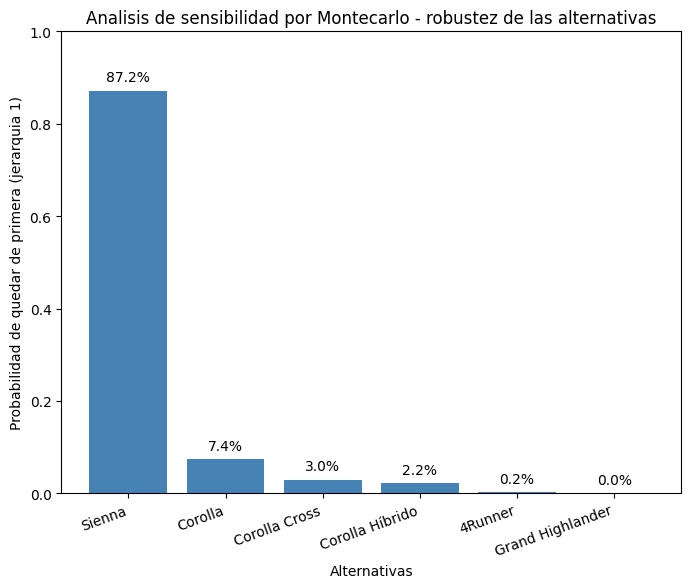

In [36]:
# Grafico de la probabilidad de que cada alternativa quede en el primer lugar
plt.figure(figsize=(8, 6))
plt.bar(sensibilidad.index, sensibilidad["Probabilidad de ser #1"], color="steelblue")
plt.ylabel("Probabilidad de quedar de primera (jerarquia 1)")
plt.xlabel("Alternativas")
plt.title("Analisis de sensibilidad por Montecarlo - robustez de las alternativas")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha='right')
for i, v in enumerate(sensibilidad["Probabilidad de ser #1"]):
    plt.text(i, v + 0.02, f"{v:.1%}", ha="center")
plt.show()

### Montecarlo alrededor de mis pesos

La simulación anterior usa pesos uniformes entre 0 y 1, es decir, pesos que pueden quedar muy lejos de los míos. En la plantilla también está la opción de la distribución de Dirichlet centrada en `vector_pesos_globales` (la línea comentada). La corro aparte para ver qué pasa con cambios moderados alrededor de mis pesos.

In [37]:
# Misma simulacion, pero con la linea de Dirichlet activa (pesos cercanos a los mios)
np.random.seed(42)  # reproducibilidad

conteo_ganador_d = np.zeros(n_alt)
suma_rangos_d = np.zeros(n_alt)

for _ in range(N_ITER):
    pesos_sim = np.random.dirichlet(alpha)      # nuevos pesos, suman 1

    puntajes_sim = pesos_sim @ M
    ganador = np.argmax(puntajes_sim)
    conteo_ganador_d[ganador] += 1
    rangos = (-puntajes_sim).argsort().argsort() + 1
    suma_rangos_d += rangos

sensibilidad_dirichlet = pd.DataFrame({
    "Probabilidad de ser #1": (conteo_ganador_d / N_ITER).round(3),
    "Rango promedio": (suma_rangos_d / N_ITER).round(2),
}, index=alternativas_mc).sort_values("Probabilidad de ser #1", ascending=False)

print(f"Montecarlo con Dirichlet centrada en mis pesos ({N_ITER} iteraciones, concentracion={concentracion}):")
print(sensibilidad_dirichlet)

Montecarlo con Dirichlet centrada en mis pesos (500 iteraciones, concentracion=50.0):
                  Probabilidad de ser #1  Rango promedio
Corolla                            0.624            1.44
Sienna                             0.282            2.79
Corolla Híbrido                    0.086            2.92
Corolla Cross                      0.008            2.92
Grand Highlander                   0.000            4.94
4Runner                            0.000            5.99


**¿Cuál es la alternativa más robusta al cambio de pesos?**

Con la simulación de la plantilla (500 juegos de pesos uniformes entre 0 y 1) la más robusta es el **Sienna**. Queda de primero en el 87,2 % de las iteraciones y su rango promedio es 1,27. El Corolla, que gana con mis pesos, solo queda de primero en el 7,4 % y tiene rango promedio 3,32.

La razón se ve en la matriz normalizada. El Sienna solo tiene un valor malo, el precio. Es el mejor en mantenimiento, en seguridad y en pasajeros, y el segundo en combustible y en carga. Cuando los pesos se sortean, el precio pesa en promedio lo mismo que los demás criterios, y al Sienna le basta con ir bien en los otros cinco. El Corolla tiene cero en carga y en pasajeros, así que solo gana cuando el costo pesa mucho, que es justo mi caso.

Con la distribución de Dirichlet centrada en mis pesos (cambios moderados) el Corolla queda de primero en el 62,4 % de las iteraciones, con rango promedio 1,44, y el Sienna en el 28,2 %. Es decir, si mis preferencias se mueven poco, el Corolla se mantiene la mayoría de las veces. Si cambian bastante, la opción más segura es el Sienna.

Usé 500 iteraciones, las que trae la plantilla, que son más de las 30 que pone como ejemplo el enunciado.

%RELLENAR%
# Preguntas de análisis - Taller 1


1.	Introduzca deliberadamente un juicio inconsistente en la primera matriz de comparaciones pareadas y observe cómo aumentan λmax y CR. ¿Qué concluye?.

2.	Los pesos se obtienen de normalizar por columnas y promediar por filas de la matriz de comparaciones. Según si propia deducción, porqué,  de una matriz de comparaciones pareadas, se puede deducir la importancia relativa de cada criterio de esa forma (no use Chat de IA)?

____________________________________________________________________________

3.	La matriz de consecuencias se normaliza dos veces (min-max y luego por suma de filas). ¿Qué logra cada normalización y por qué es necesario multiplicar por -1 los criterios a minimizar antes de normalizar?

4.	AHP usa una regla de decisión compensatoria: una gran desventaja en un criterio puede compensarse con una gran ventaja en otro. ¿En qué situaciones esto podría llevar a una mala decisión? ¿Qué método alternativo mitigaría este efecto?

5.	¿Por qué el umbral de aceptación de Saaty es CR≤0.10 y no, por ejemplo, 0? ¿Qué significaría exigir consistencia perfecta a un decisor humano?

6.	En el análisis de sensibilidad, ¿qué diferencia hay entre una alternativa que gana con alta probabilidad y una que tiene buen rango promedio pero baja probabilidad de ser la primera? ¿Cuál preferiría y por qué?

7.	Compare la sensibilidad manual (cambiar un peso a la vez) con la simulación de Montecarlo (cambiar todos los pesos simultáneamente). ¿Qué información aporta cada enfoque sobre la robustez de la decisión?



## Respuestas

### Pregunta 1. Juicio inconsistente en la primera matriz

En mi matriz de criterios el orden es Costo > Seguridad > Capacidad. Para dañarla a propósito cambio solo el juicio Costo vs Capacidad (posición [0, 2]) y voy diciendo que la capacidad es cada vez más importante que el costo. Eso contradice los otros dos juicios, que no toco.

In [38]:
valores_prueba = [3, 1, 1/3, 1/5, 1/7, 1/9]
filas_inconsistencia = []
for valor in valores_prueba:
    matriz_prueba = matriz_Criterios.copy()
    matriz_prueba[0, 2] = valor
    matriz_prueba[2, 0] = 1 / valor
    res = analizar_consistencia(matriz_prueba, f"Costo vs Capacidad = {valor:.3f}")
    pesos_prueba, _ = calcular_pesos(matriz_prueba)
    filas_inconsistencia.append({"Costo vs Capacidad": round(valor, 3),
                                 "lambda_max": round(res["lambda_max"], 4),
                                 "CR": round(res["CR"], 4),
                                 "Peso Costo": round(pesos_prueba[0], 3),
                                 "Peso Seguridad": round(pesos_prueba[1], 3),
                                 "Peso Capacidad": round(pesos_prueba[2], 3)})

tabla_inconsistencia = pd.DataFrame(filas_inconsistencia)
print()
print(tabla_inconsistencia.to_string(index=False))

[Costo vs Capacidad = 3.000]  N=3  lambda_max=3.0092  IC=0.0046  IA=0.58  CR=0.0079  -> Consistencia ACEPTABLE (CR<=0.10)
[Costo vs Capacidad = 1.000]  N=3  lambda_max=3.2174  IC=0.1087  IA=0.58  CR=0.1874  -> INCONSISTENTE (CR>0.10): revisar juicios
[Costo vs Capacidad = 0.333]  N=3  lambda_max=3.7262  IC=0.3631  IA=0.58  CR=0.6261  -> INCONSISTENTE (CR>0.10): revisar juicios
[Costo vs Capacidad = 0.200]  N=3  lambda_max=4.0828  IC=0.5414  IA=0.58  CR=0.9335  -> INCONSISTENTE (CR>0.10): revisar juicios
[Costo vs Capacidad = 0.143]  N=3  lambda_max=4.3659  IC=0.6830  IA=0.58  CR=1.1775  -> INCONSISTENTE (CR>0.10): revisar juicios
[Costo vs Capacidad = 0.111]  N=3  lambda_max=4.6048  IC=0.8024  IA=0.58  CR=1.3834  -> INCONSISTENTE (CR>0.10): revisar juicios

 Costo vs Capacidad  lambda_max     CR  Peso Costo  Peso Seguridad  Peso Capacidad
              3.000      3.0092 0.0079       0.540           0.297           0.163
              1.000      3.2174 0.1874       0.413           0.327

**Qué concluyo.** Con mi juicio original (3) λmax = 3,0092 y CR = 0,0079. Basta con bajar ese juicio a 1, o sea decir que costo y capacidad pesan igual, para que λmax suba a 3,2174 y el CR a 0,1874, que ya pasa el límite de 0,10. Si sigo hasta decir que la capacidad es absolutamente más importante que el costo (1/9), λmax llega a 4,6048 y el CR a 1,3834. Un CR mayor que 1 significa que la matriz es más inconsistente que una llenada al azar en promedio.

1. λmax solo vale n (aquí 3) cuando los juicios son consistentes. Cada vez que un juicio contradice a los otros, λmax se aleja de n y el CR sube.
2. Un solo juicio contradictorio basta para que la matriz no pase la prueba, así que el CR sí sirve para detectar errores.
3. La inconsistencia también cambia los pesos. La capacidad pasa de 0,163 a 0,507 y queda como el criterio más importante, aunque los otros dos juicios dicen que es el menos importante. Si no reviso el CR, ese error se va directo a la decisión. Se arregla devolviendo el juicio a un valor coherente con los otros dos, como el 3 que tenía.

### Pregunta 2. ¿Por qué normalizar por columnas y promediar por filas da la importancia relativa?

Lo pensé primero con una matriz perfectamente consistente. Si los pesos reales de los criterios son $w_1, w_2, w_3$, cada juicio es la razón entre dos pesos: $a_{ij} = w_i / w_j$. Entonces la columna $j$ es $(w_1/w_j,\ w_2/w_j,\ w_3/w_j)$, o sea, el mismo vector de pesos dividido por un número fijo, $w_j$. Cada columna ya trae los pesos, solo que medidos con el criterio $j$ como unidad.

Al dividir la columna por su suma, ese número fijo se cancela. La suma de la columna es $(w_1 + w_2 + w_3)/w_j$, y al dividir cada elemento queda $w_i/(w_1 + w_2 + w_3)$, que es la parte del total que le toca a cada criterio. Por eso, si la matriz es consistente, todas las columnas normalizadas son iguales y son justo los pesos. Se ve en la matriz ideal del cuaderno (pesos 0,5; 0,3 y 0,2): sus columnas suman 2; 3,33 y 5, y al normalizarlas las tres quedan en 0,5; 0,3 y 0,2.

En una matriz real los juicios no son perfectos y cada columna da una estimación un poco distinta. Cada columna responde a la pregunta "si este criterio vale 1, ¿cuánto valen los demás?". Promediar por filas junta esas estimaciones en una sola, y los errores pequeños de un juicio se compensan con los de los otros. En la celda de abajo se ve con mi matriz de criterios: para Costo las tres columnas dan 0,5455, 0,5714 y 0,5, y el promedio es 0,539. Las columnas no coinciden del todo porque mi matriz no es perfectamente consistente, pero están cerca, y el promedio casi no se aleja del vector propio (la diferencia máxima entre los dos métodos es 0,00065).

Esto también explica por qué se revisa el CR antes: el método funciona porque las columnas dan estimaciones parecidas. Si la matriz fuera muy inconsistente, cada columna diría algo distinto y el promedio no representaría bien la importancia de ningún criterio.

In [39]:
# Pregunta 2: columnas normalizadas de mi matriz de criterios
nombres_criterios = ['Costo', 'Seguridad', 'Capacidad']
print("Suma de cada columna:", matriz_Criterios.sum(axis=0).round(4))

columnas_normalizadas = matriz_Criterios / matriz_Criterios.sum(axis=0)
print(pd.DataFrame(columnas_normalizadas,
                   index=nombres_criterios,
                   columns=['Col. Costo', 'Col. Seguridad', 'Col. Capacidad']).round(4))

print("\nPromedio por filas:", columnas_normalizadas.mean(axis=1).round(4))
print("Vector propio     :", np.round(pesos_criterios, 4))

Suma de cada columna: [1.8333 3.5    6.    ]
           Col. Costo  Col. Seguridad  Col. Capacidad
Costo          0.5455          0.5714          0.5000
Seguridad      0.2727          0.2857          0.3333
Capacidad      0.1818          0.1429          0.1667

Promedio por filas: [0.539  0.2973 0.1638]
Vector propio     : [0.5396 0.297  0.1634]


### Pregunta 3. Las dos normalizaciones y el signo negativo

La primera normalización (min-max) quita las unidades. Los criterios vienen en dólares, estrellas, pies cúbicos y personas, y así no se pueden sumar. Con min-max cada criterio queda entre 0 y 1, con 1 para el mejor carro y 0 para el peor.

La segunda normalización divide cada fila por su suma, para que cada criterio reparta una unidad entre los seis carros. Así se cumple la regla del AHP de que cada nodo padre reparte 1 entre sus hijos, y lo máximo que un criterio puede aportar al puntaje es su peso global. En mis datos esto tiene un efecto: en seguridad cinco carros tienen cinco estrellas y cada uno recibe 0,2, mientras que en pasajeros solo dos tienen ocho puestos y cada uno recibe 0,5. Cuando muchos carros comparten el mejor valor, a cada uno le toca menos.

El signo negativo hace falta porque min-max le da 1 al número más grande, y en un costo el número más grande es el peor. Sin el cambio de signo el 4Runner, que es el más caro (43.365 USD), recibiría 1 en precio y el Corolla, que es el más barato, recibiría 0. Con el signo negativo el costo más bajo queda como el número más grande y recibe el 1.

### Pregunta 4. Regla compensatoria

En AHP el puntaje es una suma ponderada, así que un mal valor en un criterio se puede tapar con buenos valores en otros. Eso lleva a malas decisiones cuando hay requisitos mínimos que no se negocian. Por ejemplo:

* **Puestos mínimos.** El Corolla gana con cinco puestos y la menor carga (13,1 pies cúbicos) porque su precio lo compensa. Si en mi familia fuéramos siete, el AHP me seguiría recomendando un carro que no me sirve.
* **Seguridad mínima.** En mis datos todos tienen cuatro o cinco estrellas, pero con otros carros uno de dos o tres estrellas podría ganar solo por ser barato.
* **Tope de presupuesto.** Un carro que se pasa del dinero que tengo podría ganar por ser muy bueno en todo lo demás.

Para reducir este efecto hay varias opciones:

* Filtrar primero con umbrales mínimos (regla conjuntiva) y aplicar el AHP solo a los carros que pasan.
* Usar un método de superación como ELECTRE, que tiene umbrales de veto: si una alternativa es demasiado mala en un criterio, no puede superar a otra por buena que sea en los demás.
* Programación de compromiso con p = ∞, que usamos en el taller anterior. Ahí solo cuenta la mayor distancia al ideal, y no hay compensación entre criterios.
* Lo que muestra la consideración adicional al final del cuaderno: elevar los valores normalizados a un exponente E < 1. Con mis pesos y E = 0,1 el orden cambia: el Sienna pasa al primer lugar (0,8210), el Corolla Cross queda segundo (0,7670) y el Corolla baja al tercero (0,7289). Pasa porque el Corolla tiene ceros en carga y pasajeros, y al bajar la compensación esos ceros pesan más.

### Pregunta 5. ¿Por qué CR ≤ 0,10 y no 0?

Porque las personas no juzgamos de forma perfectamente consistente, y además la escala muchas veces no lo permite.

1. **La escala es discreta.** Solo hay enteros del 1 al 9 y sus recíprocos. En mi matriz, si Costo vale 2 veces Seguridad y Seguridad 2 veces Capacidad, la consistencia pide 4 entre Costo y Capacidad. Yo puse 3 porque es lo que pienso, y eso da CR = 0,0079. Hay casos peores: si A vale 3 veces B y B vale 5 veces C, A tendría que valer 15 veces C, y ese número no está en la escala.
2. **El CR compara contra el azar.** El IA es el IC promedio de matrices llenadas al azar. Un CR de 0,10 quiere decir que la inconsistencia es la décima parte de la que tendría alguien que responde al azar. Saaty lo propuso como regla práctica: la inconsistencia debe ser un orden de magnitud menor que la consistencia. Es un límite empírico, no una demostración.
3. **Algo de inconsistencia es normal.** Saaty (2003) explica que obligar a la consistencia sería pedir que las personas actúen como robots que no pueden cambiar de opinión con información nueva. Además, cuando una matriz ya es casi consistente no hay una forma clara de saber qué juicio mover ni cuánto, y forzar esos ajustes puede dañar los pesos.

Exigir consistencia perfecta a un decisor humano sería pedirle que se comporte como una calculadora. Bastaría con hacer n − 1 comparaciones y sacar las demás multiplicando, y se perdería la redundancia de comparar todos los pares, que es lo que permite detectar errores como el de la pregunta 1. Lo importante es que los juicios no se contradigan, y eso es lo que controla el límite de 0,10.

### Pregunta 6. Probabilidad de ganar frente a rango promedio

La probabilidad de ser #1 solo mira el primer puesto. El rango promedio mira todos los puestos, así que premia a la alternativa que casi nunca queda mal aunque gane pocas veces.

En la simulación uniforme se ve la diferencia. El Corolla Cross gana solo el 3,0 % de las veces, pero su rango promedio es 2,92, el segundo mejor después del Sienna. El Corolla gana más veces (7,4 %) pero su rango promedio es peor (3,32): cuando no gana suele quedar lejos, por sus ceros en carga y pasajeros.

Lo ideal es tener las dos cosas, como el Sienna en la simulación uniforme (87,2 % y 1,27) o el Corolla en la de Dirichlet alrededor de mis pesos (62,4 % y 1,44). Si tuviera que escoger, me fijaría más en el rango promedio, porque al comprar un carro me preocupa más no quedar con una mala opción que tener siempre la mejor. Una alternativa que casi siempre queda segunda es una compra razonable en casi cualquier escenario.

### Pregunta 7. Sensibilidad manual frente a Montecarlo

La sensibilidad manual mueve un peso a la vez. Dice exactamente a qué criterio es sensible la decisión y desde qué punto cambia: en mi caso, bajar el peso del precio un 20 % o subir el de pasajeros un 34 % le da el primer lugar al Sienna. Su limitación es que no prueba cambios en varios pesos al mismo tiempo, que es lo que pasa cuando uno de verdad cambia de opinión.

Montecarlo cambia todos los pesos a la vez muchas veces y da probabilidades de ganar y rangos promedio. Muestra qué tan estable es la decisión en general, pero no dice qué criterio provoca el cambio. Además el resultado depende de cómo se sorteen los pesos: con pesos uniformes gana el Sienna (87,2 %) y con Dirichlet alrededor de mis pesos gana el Corolla (62,4 %).

Los dos se complementan: el manual explica por qué cambia la decisión y Montecarlo mide qué tan probable es que cambie.

# Consideración adicional


> **Nota:** las dos ideas siguientes **no forman parte del AHP clásico**. Se incluyen como consideración adicional para tenerlas presentes.


### 1. Criterio cualitativo con escala

**¿Dónde iría?** En los pasos 4–6 (valoración y normalización de la matriz de consecuencias), cuando un criterio **no es numérico**. En el caso del tipo de carro como *Sedan, Crossover,etc*. Antes de poder normalizar, se traduce cada categoría a un número mediante una **escala ordinal fija** (por ejemplo 0, 0.25, 0.50, 0.75, 1.00). A partir de ahí el criterio entra al mismo flujo de normalización que los demás.

**Implicación.** Es una ventaja de AHP: permite mezclar criterios cuantitativos y cualitativos. Pero la escala elegida es una **decisión subjetiva del decisor**, no un dato objetivo: cambiar los valores de la escala puede alterar la jerarquía. Debe justificarse.

### 2. Exponente de la función de valor (control de compensación)

**¿Dónde iría?** Entre la segunda normalización (paso 7) y la ponderación (paso 8). Cada valor normalizado se eleva a un **exponente $E$** antes de multiplicarlo por el peso global:

$$C_{AHP}(A_j) = \sum_{i} w_i \, \left(Z'_{ij}\right)^{E}$$

- $E = 1$ >> **AHP clásico**, totalmente **compensatorio**: un valor muy bajo en un criterio puede compensarse con uno muy alto en otro.
- $E < 1$ >> función de valor **cóncava**: penaliza más los valores bajos, **atenuando la compensación**.

**Implicación.** El exponente es una "perilla" que acerca el AHP hacia métodos **menos compensatorios** (como la Programación de Compromiso, ojo en esta el exponente debe ser mayor de 1 porque es para minimizar distancia al ideal), abordando justamente la desventaja del AHP: que grandes deficiencias se compensen con grandes virtudes.


In [40]:

# --- Idea adicional: exponente de la funcion de valor sobre el caso del carro ---
def puntajes_con_exponente(matriz_norm, pesos, exponente):
    """Calificacion AHP aplicando un exponente a los valores normalizados
       antes de ponderar por los pesos globales."""
    M = matriz_norm.values                      # criterios x alternativas
    puntajes = pesos @ (M ** exponente)
    return pd.Series(puntajes, index=matriz_norm.columns)

print("\n2) Efecto del exponente de la funcion de valor (caso carro):")
for E in [1.0, 0.1]:
    p = puntajes_con_exponente(matriz_2normalizada, vector_pesos_globales, E)
    jer = p.rank(ascending=False).astype(int)
    etiqueta = "AHP clasico (compensatorio)" if E == 1.0 else "atenua la compensacion"
    print(f"\n   Exponente E={E} -> {etiqueta}")
    print(pd.DataFrame({"Puntaje": p.round(4), "Jerarquia": jer}).sort_values("Jerarquia").to_string())



2) Efecto del exponente de la funcion de valor (caso carro):

   Exponente E=1.0 -> AHP clasico (compensatorio)
                  Puntaje  Jerarquia
Corolla            0.2169          1
Corolla Cross      0.2044          2
Corolla Híbrido    0.2043          3
Sienna             0.1985          4
Grand Highlander   0.1278          5
4Runner            0.0481          6

   Exponente E=0.1 -> atenua la compensacion
                  Puntaje  Jerarquia
Sienna             0.8210          1
Corolla Cross      0.7670          2
Corolla            0.7289          3
Grand Highlander   0.6980          4
Corolla Híbrido    0.6557          5
4Runner            0.1274          6


In [41]:
#PARA MAYOR INFORMACION, SI SE TIENE UN CRITERIOS CUALITATIVO CON ESCALA POR EJEMPLO TIPO DE VEHICULO
# Escala ordinal -> numerica (misma logica de la clase para criterios cualitativos)
escala_cualitativa = {"Hatchback": 0.6, "Sedan": 0.7, "Crossover": 0.8,
                      "SUVCompacta": 0.9, "SUVmediana": 1.00}

# Ejemplo: una columna cualitativa hipotetica para 3 alternativas
valores_cualitativos = ["Hatchback", "Crossover", "SUVmediana"]
valores_numericos = [escala_cualitativa[v] for v in valores_cualitativos]
print("1) Criterio cualitativo mapeado a numerico:")
print("   ", dict(zip(valores_cualitativos, valores_numericos)))
print("   (estos numeros luego entran a la normalizacion como cualquier otro criterio)")


1) Criterio cualitativo mapeado a numerico:
    {'Hatchback': 0.6, 'Crossover': 0.8, 'SUVmediana': 1.0}
   (estos numeros luego entran a la normalizacion como cualquier otro criterio)
